# Biology for CS: Genome Browsers and Biological Databases

## Exercise 1: Exploring NCBI Gene Database
The (US-based) National Center for Biotechnology Information (NCBI) maintains comprehensive databases of genomic information. The Gene database provides gene-specific information including genomic context, expression, and function.

### Task
Use the NCBI E-utilities API through Biopython to:
1. Search for the primary ID corresponding to the human gene **BRCA1** (breast cancer susceptibility gene) in the [gene database](https://www.ncbi.nlm.nih.gov/gene) 
   - use the `read` function to parse the XML handle
2. Fetch information about this gene
   - play around with [different settings](www.ncbi.nlm.nih.gov/books/NBK25499/table/chapter4.T._valid_values_of__retmode_and/?report=objectonly) for `rettype` and `retmode` to find an output format you like 
   - you may need to use `handle.read()` instead of `Entrez.read()` for some formats
3. Fetch information about this gene in `xml` format and familiarise yourself with the available keys
   - extract fields `Gene-ref_maploc` and `Gene-ref_desc`
   - what is the main function of BRCA1 according to the description? Research a bit further, what is this gene associated with? 
   - where is the gene located in our genome? 

The Entrez [documentation](https://biopython.org/docs/latest/api/Bio.Entrez.html) can be helpful. 

In [ ]:
from Bio import Entrez
import json

Entrez.email = "A.N.Other@example.com"  # Always tell NCBI who you are
stream = Entrez.einfo()
record = Entrez.read(stream)
stream.close()

sorted(record.keys())

['DbInfo', 'DbList', 'ERROR']

In [5]:
record["DbList"]

['pubmed', 'protein', 'nuccore', 'ipg', 'nucleotide', 'structure', 'genome', 'gap', 'grasp', 'annotinfo', 'assembly', 'bioproject', 'biosample', 'blastdbinfo', 'books', 'cdd', 'clinvar', 'dbvar', 'gene', 'gds', 'geoprofiles', 'medgen', 'mesh', 'nlmcatalog', 'omim', 'orgtrack', 'pmc', 'proteinclusters', 'pcassay', 'protfam', 'pccompound', 'pcsubstance', 'seqannot', 'snp', 'sra', 'taxonomy', 'biocollections', 'gtr']

In [19]:
stream = Entrez.esearch(db="gene", term="BRCA1[Gene Name] AND Homo sapiens[Organism]", retmax="40", rettype="gene_table")
record = Entrez.read(stream)
gene_id = record["IdList"][0]
record

{'Count': '1', 'RetMax': '1', 'RetStart': '0', 'IdList': ['672'], 'TranslationSet': [{'From': 'Homo sapiens[Organism]', 'To': '"Homo sapiens"[Organism]'}], 'TranslationStack': [{'Term': 'BRCA1[Gene Name]', 'Field': 'Gene Name', 'Count': '688', 'Explode': 'N'}, {'Term': '"Homo sapiens"[Organism]', 'Field': 'Organism', 'Count': '360697', 'Explode': 'Y'}, 'AND'], 'QueryTranslation': 'BRCA1[Gene Name] AND "Homo sapiens"[Organism]'}

In [ ]:
stream = Entrez.efetch(db="gene", id=gene_id, rettype="docsum", retmode="text")
print(stream.read())

# Very large data set
#stream = Entrez.efetch(db="gene", id=gene_id, rettype="gene_table", retmode="text")
#print(stream.read())


1. BRCA1
Official Symbol: BRCA1 and Name: BRCA1 DNA repair associated [Homo sapiens (human)]
Other Aliases: BRCAI, BRCC1, BROVCA1, FANCS, IRIS, PNCA4, PPP1R53, PSCP, RNF53
Other Designations: breast cancer type 1 susceptibility protein; BRCA1/BRCA2-containing complex, subunit 1; Fanconi anemia, complementation group S; RING finger protein 53; breast and ovarian cancer susceptibility protein 1; breast cancer 1, early onset; early onset breast cancer 1; protein phosphatase 1, regulatory subunit 53
Chromosome: 17; Location: 17q21.31
Annotation: Chromosome 17 NC_000017.11 (43044295..43170327, complement)
MIM: 113705
ID: 672




In [25]:
import json
stream = Entrez.efetch(db="gene", id=gene_id, retmode="xml")
record = Entrez.read(stream)[0]

In [26]:
record.keys()

dict_keys(['Entrezgene_track-info', 'Entrezgene_type', 'Entrezgene_source', 'Entrezgene_gene', 'Entrezgene_prot', 'Entrezgene_summary', 'Entrezgene_location', 'Entrezgene_gene-source', 'Entrezgene_locus', 'Entrezgene_properties', 'Entrezgene_comments', 'Entrezgene_unique-keys', 'Entrezgene_xtra-index-terms', 'Entrezgene_xtra-properties'])

In [27]:
record["Entrezgene_gene"].keys()

dict_keys(['Gene-ref'])

In [28]:
record["Entrezgene_gene"]["Gene-ref"].keys()

dict_keys(['Gene-ref_locus', 'Gene-ref_desc', 'Gene-ref_maploc', 'Gene-ref_db', 'Gene-ref_syn', 'Gene-ref_formal-name'])

In [30]:
print(record["Entrezgene_gene"]["Gene-ref"]["Gene-ref_maploc"])
print(record["Entrezgene_gene"]["Gene-ref"]["Gene-ref_desc"])
print(record["Entrezgene_summary"])

17q21.31
BRCA1 DNA repair associated
This gene encodes a 190 kD nuclear phosphoprotein that plays a role in maintaining genomic stability, and it also acts as a tumor suppressor. The BRCA1 gene contains 22 exons spanning about 110 kb of DNA. The encoded protein combines with other tumor suppressors, DNA damage sensors, and signal transducers to form a large multi-subunit protein complex known as the BRCA1-associated genome surveillance complex (BASC). This gene product associates with RNA polymerase II, and through the C-terminal domain, also interacts with histone deacetylase complexes. This protein thus plays a role in transcription, DNA repair of double-stranded breaks, and recombination. Mutations in this gene are responsible for approximately 40% of inherited breast cancers and more than 80% of inherited breast and ovarian cancers. Alternative splicing plays a role in modulating the subcellular localization and physiological function of this gene. Many alternatively spliced transc

Chromosome 17, long arm

This gene encodes a 190 kD nuclear phosphoprotein that plays a role in **maintaining genomic stability**, and it also acts as a **tumor suppressor**. The BRCA1 gene contains 22 exons spanning about 110 kb of DNA. The encoded protein combines with other tumor suppressors, DNA damage sensors, and signal transducers to form a large multi-subunit protein complex known as the BRCA1-associated genome surveillance complex (BASC). This gene product associates with RNA polymerase II, and through the C-terminal domain, also interacts with histone deacetylase complexes. This protein thus **plays a role in transcription**, **DNA repair of double-stranded breaks**, and **recombination**. Mutations in this gene are **responsible for approximately 40% of inherited breast cancers** and more than 80% of inherited breast and ovarian cancers. Alternative splicing plays a role in modulating the subcellular localization and physiological function of this gene. Many alternatively spliced transcript variants, some of which are disease-associated mutations, have been described for this gene, but the full-length natures of only some of these variants has been described. A related pseudogene, which is also located on chromosome 17, has been identified. [provided by RefSeq, May 2020]

## Exercise 2: Working with Ensembl REST API
Ensembl is a genome browser that provides annotated genomes for vertebrates and model organisms. The Ensembl REST API allows programmatic access to genomic data.

### Task
1. Use the Ensembl REST API gene lookup endpoint to retrieve information about the human TP53 gene (tumor protein p53)
    - extract the Ensembl gene ID, description, and location in the genome
2. Get the genomic sequence of TP53
3. Investigate the transcripts of TP53 available in this database
    - how many transcripts are there? 
    - how many of them code for proteins? 
4. Visualize the transcript lengths and the number of exons in each transcripts as histograms
5. Briefly summarise what you know about alternative splicing and how it relates to genes having multiple transcript variants

**NOTE**
- Gene lookup: `https://rest.ensembl.org/lookup/symbol/homo_sapiens/{gene_name}`
- Sequence: `https://rest.ensembl.org/sequence/id/{gene_id}`
- Transcripts: Gene lookup includes transcript information if using `requests` with `params={"expand": 1}`

In [ ]:
import requests

headers = {"Content-Type": "application/json"}

r = requests.get("https://rest.ensembl.org/lookup/symbol/homo_sapiens/TP53",
                 headers=headers, 
                 params={"expand": 1})
gene = r.json()



ENSG00000141510


In [3]:
print(gene.keys())

dict_keys(['assembly_name', 'end', 'start', 'Transcript', 'seq_region_name', 'biotype', 'version', 'db_type', 'object_type', 'species', 'source', 'logic_name', 'strand', 'canonical_transcript', 'description', 'id', 'display_name'])


In [11]:

gene_id = gene["id"]
print(gene_id)
print(gene["description"])
print(gene["seq_region_name"], gene["start"], gene["end"], gene["strand"])

ENSG00000141510
tumor protein p53 [Source:HGNC Symbol;Acc:HGNC:11998]
17 7661779 7687546 -1


In [6]:
r = requests.get(f"https://rest.ensembl.org/sequence/id/{gene_id}", headers={"Content-Type": "text/plain"})
seq = r.text
print(len(seq))
print(f"{seq[:100]}...")

25768
GGATTGGGGTTTTCCCCTCCCATGTGCTCAAGACTGGCGCTAAAAGTTTTGAGCTTCTCAAAAGTCTAGAGCCACCGTCCAGGGAGCAGGTAGCTGCTGG...


In [13]:
transcripts = gene["Transcript"]
print(len(transcripts))
print(transcripts[0].keys())
coding = [t for t in transcripts if t["biotype"] == "protein_coding"]
print(len(coding))

40
dict_keys(['start', 'end', 'Parent', 'assembly_name', 'version', 'db_type', 'biotype', 'gencode_primary', 'length', 'seq_region_name', 'logic_name', 'strand', 'ens_canon_extended', 'source', 'is_canonical', 'object_type', 'Exon', 'species', 'display_name', 'id', 'Translation'])
34


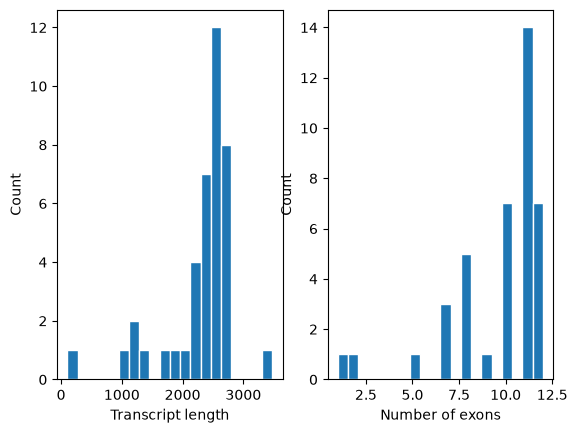

In [17]:
import matplotlib.pyplot as plt

# spliced length = sum of exon lengths
lengths = [sum(e["end"] - e["start"] + 1 for e in t["Exon"]) for t in transcripts]
n_exons = [len(t["Exon"]) for t in transcripts]

fig, axes = plt.subplots(1, 2)
axes[0].hist(lengths, bins=20, edgecolor="white")
axes[0].set_xlabel("Transcript length")
axes[0].set_ylabel("Count")

axes[1].hist(n_exons, 20, edgecolor="white")
axes[1].set_xlabel("Number of exons")
axes[1].set_ylabel("Count")
plt.show()

Alternative Splicing:

- Gene made out of exons + introns
- mRNA copies all, then introns are excluded
- Additionally some exons can be excluded
- Order of exons stays the same

## Exercise 3: Working with UniProt REST API
UniProt is a comprehensive resource for protein sequence and functional information. It integrates data from multiple sources and provides detailed annotations.

### Task
1. Query UniProt for TP53
    - how many results come up, and which organisms do they belong to? 
    - extract the full recommended names of the human proteins that came up in your search. Which one corresponds to the protein product of the TP53 gene we looked at in Exercise 2? 
    - extract the primary accession key of the correct TP53 product
2. Retrieve the length and sequence of this protein
3. Find alternative isoform products of the TP53 gene by checking the comments
    - how many alternative isoforms are listed? 
    - compare this number to the number of protein-coding transcripts you identified in Exercise 2. What could cause this discrepancy? 

**NOTE**
- Search: `https://rest.uniprot.org/uniprotkb/search?query={query}&format=json`
- Accession ID lookup: `https://rest.uniprot.org/uniprotkb/{id}.json`

In [ ]:
import requests
